# Simultaneous Perturbation Stochastic Approximation (SPSA)
## Mathematical Optimization & Forward-Only Deep Learning Without Backpropagation

**Implementation by**: Ananth Shyam, Rama Narasimha, and Mahan Bhimireddy  
**Reference Paper**: *B. Wulff, J. Schuecker, C. Bauckhage. SPSA for Layer-Wise Training of Deep Networks. ICANN 2018, LNCS 11141, pp. 564–573.*

This notebook demonstrates **Simultaneous Perturbation Stochastic Approximation (SPSA)** across two core domains:
1. **Part 1: Continuous Function Optimization**: Non-convex optimization on a coupled cubic polynomial landscape.
2. **Part 2: Deep Neural Network Classification**: Non-linear binary classification on concentric circles without backpropagation.

### Core Evaluated Optimizers (Across Both Parts):
1. **Holistic SPSA** (Spall 1992, 1998): Derivative-free, simultaneous perturbation across all parameters (2 forward evals/step; 0 backprop).
2. **Layer-Wise SPSA** (Wulff et al., ICANN 2018): Derivative-free, layer-by-layer perturbation while freezing remaining parameters (0 backprop).
3. **GD (Gradient Descent)**: Full-batch analytical gradient descent using PyTorch's built-in `torch.optim.SGD`.
4. **SGD (Stochastic Gradient Descent)**: Mini-batch / stochastic gradient descent using PyTorch's built-in `torch.optim.SGD`.


## 1. Theoretical Background & Mathematical Formulation

### 1.1 The Classical SPSA Algorithm (Spall 1992/1998)
Standard gradient approximation techniques like Finite Differences require $2D$ function evaluations to approximate a $D$-dimensional gradient vector:
$$\hat{g}_i = \frac{f(\theta + c \mathbf{e}_i) - f(\theta - c \mathbf{e}_i)}{2c}$$
In deep networks where $D \sim 10^4 - 10^9$, Finite Differences is computationally intractable.

**SPSA solves this by perturbing all $D$ parameters simultaneously** using a random Rademacher vector $\Delta_k \in \{-1, +1\}^D$:
$$\hat{g}_{ki}(\theta_k) = \frac{f(\theta_k + c_k \Delta_k) - f(\theta_k - c_k \Delta_k)}{2 c_k \Delta_{ki}} = \frac{y_k^+ - y_k^-}{2 c_k} \Delta_{ki}$$
Because only **two forward evaluations** ($y_k^+, y_k^-$) are required per iteration regardless of $D$, SPSA provides an asymptotic $O(D)$ speedup.

### 1.2 The Curse of Dimensionality & Layer-Wise SPSA (Wulff et al. ICANN 2018)
When applied to multi-layer neural networks (Holistic SPSA), the variance of the gradient approximation scales linearly with the total dimension:
$$\text{Var}(\hat{g}_{ki}) \propto D$$
As depth grows, perturbation signals from one layer act as catastrophic noise for other layers, diluting the gradient update and causing training to stall.

**Layer-Wise SPSA** (Wulff et al., 2018) solves this dilemma by decomposing the global optimization problem into layer-by-layer subproblems:
- For layer $l \in \{1, \dots, L\}$, freeze all other layers $j \neq l$.
- Perturb strictly the weights $W_l$ and biases $b_l$ of layer $l$:
  $$\hat{g}_{l, i} = \frac{L(W_l + c_t \Delta_l) - L(W_l - c_t \Delta_l)}{2 c_t \Delta_{l, i}}$$
- Apply $t_{\text{max}}$ updates to layer $l$ before moving to layer $l+1$.
This reduces the perturbation variance from $O(D)$ down to $O(d_l)$, enabling stable, deep neural network training without any backpropagation!


In [1]:
# Environment Setup and Imports
import time
from typing import Callable, Dict, List, Tuple
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
import torch
import torch.nn as nn

# Fix seeds for absolute reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print('Environment initialized successfully.')
print(f'PyTorch version: {torch.__version__} | Matplotlib and NumPy loaded.')


Environment initialized successfully.
PyTorch version: 2.6.0+cu124 | Matplotlib and NumPy loaded.


## 2. Part 1: Mathematical Optimization on a Complex Function

We evaluate the **4 core optimizers** on a challenging non-convex landscape:
1. **Holistic SPSA** (Spall 1992/1998 simultaneous perturbation; strictly 2 forward evals/step)
2. **Layer-Wise SPSA** (Coordinate-wise perturbation; decoupled parameter updates)
3. **GD (Gradient Descent)** (Exact analytical calculus gradient)
4. **SGD (Stochastic Gradient Descent)** (Stochastic gradient evaluations with zero-mean noise)

### Selected Landscape: Coupled Non-Convex Cubic Polynomial
$$f(x, y) = x^3 + y^3 - 3xy + 1.0$$

#### Why is this function ideal?
- **Pure Cubic Monomials**: Contains $x^3$ and $y^3$, with **no quadratic $x^2 + y^2$ terms**.
- **Cross-Variable Coupling**: The $-3xy$ term generates non-separable Hessian coupling ($H_{12} = H_{21} = -3$).
- **Critical Points**:
  - **Saddle Point**: $\mathbf{x}_{\text{saddle}} = (0.0, 0.0)$, $f(0, 0) = 1.0$, eigenvalues $\lambda = \pm 3$.
  - **Global Minimum**: $\mathbf{x}^* = (1.0, 1.0)$, $f(1, 1) = 0.0$, eigenvalues $\lambda = 3, 9$.
- **Analytic Gradient**:
  $$\nabla f(x, y) = \begin{bmatrix} 3x^2 - 3y \\ 3y^2 - 3x \end{bmatrix}$$
- **Starting Point**: Initialized at an asymmetric coordinate $\mathbf{x}_0 = (2.0, 0.3)$ with $f(\mathbf{x}_0) = 7.2270$.


In [2]:
class SPSAOptimizer:
    """
    SPSA Optimizer supporting both Holistic simultaneous perturbations and Coordinate/Layer-Wise updates.
    """
    def __init__(self, a=0.05, c=0.06, A=12.0, alpha=0.602, gamma=0.101, max_grad_norm=20.0, seed=42):
        self.a, self.c, self.A = a, c, A
        self.alpha, self.gamma = alpha, gamma
        self.max_grad_norm = max_grad_norm
        self.rng = np.random.default_rng(seed)

    def optimize(self, loss_fn: Callable[[np.ndarray], float], theta_init: np.ndarray, iterations: int = 150):
        """Method 1: Holistic SPSA (2 function evaluations per step)."""
        theta = np.array(theta_init, dtype=np.float64)
        history_loss, history_theta = [float(loss_fn(theta))], [theta.copy()]
        for k in range(iterations):
            ak = self.a / ((k + 1 + self.A) ** self.alpha)
            ck = self.c / ((k + 1) ** self.gamma)
            delta = self.rng.choice([-1.0, 1.0], size=theta.shape)
            yp = loss_fn(theta + ck * delta)
            ym = loss_fn(theta - ck * delta)
            g_hat = (yp - ym) / (2.0 * ck * delta)
            gnorm = np.linalg.norm(g_hat)
            if gnorm > self.max_grad_norm:
                g_hat = g_hat * (self.max_grad_norm / gnorm)
            theta = theta - ak * g_hat
            history_loss.append(float(loss_fn(theta)))
            history_theta.append(theta.copy())
        return theta, history_loss, history_theta

    def optimize_layerwise(self, loss_fn: Callable[[np.ndarray], float], theta_init: np.ndarray, iterations: int = 150):
        """Method 2: SPSA with Coordinate/Layer-Wise Update (2p evaluations per step)."""
        theta = np.array(theta_init, dtype=np.float64)
        history_loss, history_theta = [float(loss_fn(theta))], [theta.copy()]
        p = len(theta)
        for k in range(iterations):
            ak = self.a / ((k + 1 + self.A) ** self.alpha)
            ck = self.c / ((k + 1) ** self.gamma)
            for i in range(p):
                delta_i = float(self.rng.choice([-1.0, 1.0]))
                tp, tm = theta.copy(), theta.copy()
                tp[i] += ck * delta_i
                tm[i] -= ck * delta_i
                ghat_i = (loss_fn(tp) - loss_fn(tm)) / (2.0 * ck * delta_i)
                if abs(ghat_i) > self.max_grad_norm:
                    ghat_i = np.sign(ghat_i) * self.max_grad_norm
                theta[i] -= ak * ghat_i
            history_loss.append(float(loss_fn(theta)))
            history_theta.append(theta.copy())
        return theta, history_loss, history_theta


In [3]:
# Part 1: Optimization Functions and Built-in PyTorch Optimizers
def complex_cubic_func(theta: np.ndarray) -> float:
    x, y = theta[0], theta[1]
    return float(x ** 3 + y ** 3 - 3.0 * x * y + 1.0)

# 3. GD: Using PyTorch's Built-in torch.optim.SGD (Exact analytical backprop)
def run_builtin_gd(theta_init, lr=0.03, iterations=150, max_grad_norm=20.0):
    theta = torch.tensor(theta_init, dtype=torch.float32, requires_grad=True)
    opt = torch.optim.SGD([theta], lr=lr)
    history_loss = [float(complex_cubic_func(theta_init))]
    history_theta = [theta.detach().numpy().copy()]
    for _ in range(iterations):
        opt.zero_grad()
        loss = theta[0]**3 + theta[1]**3 - 3.0 * theta[0] * theta[1] + 1.0
        loss.backward()
        if max_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_([theta], max_norm=max_grad_norm)
        opt.step()
        with torch.no_grad():
            history_loss.append(float(loss.item()))
            history_theta.append(theta.detach().numpy().copy())
    return theta.detach().numpy(), history_loss, history_theta

# 4. SGD: Using PyTorch's Built-in torch.optim.SGD (with stochastic gradient noise)
def run_builtin_sgd(theta_init, lr=0.03, noise_std=0.05, iterations=150, max_grad_norm=20.0, seed=42):
    torch.manual_seed(seed)
    theta = torch.tensor(theta_init, dtype=torch.float32, requires_grad=True)
    opt = torch.optim.SGD([theta], lr=lr)
    history_loss = [float(complex_cubic_func(theta_init))]
    history_theta = [theta.detach().numpy().copy()]
    for _ in range(iterations):
        opt.zero_grad()
        loss = theta[0]**3 + theta[1]**3 - 3.0 * theta[0] * theta[1] + 1.0
        loss.backward()
        with torch.no_grad():
            theta.grad += torch.randn_like(theta.grad) * noise_std
        if max_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_([theta], max_norm=max_grad_norm)
        opt.step()
        with torch.no_grad():
            history_loss.append(float(loss.item()))
            history_theta.append(theta.detach().numpy().copy())
    return theta.detach().numpy(), history_loss, history_theta


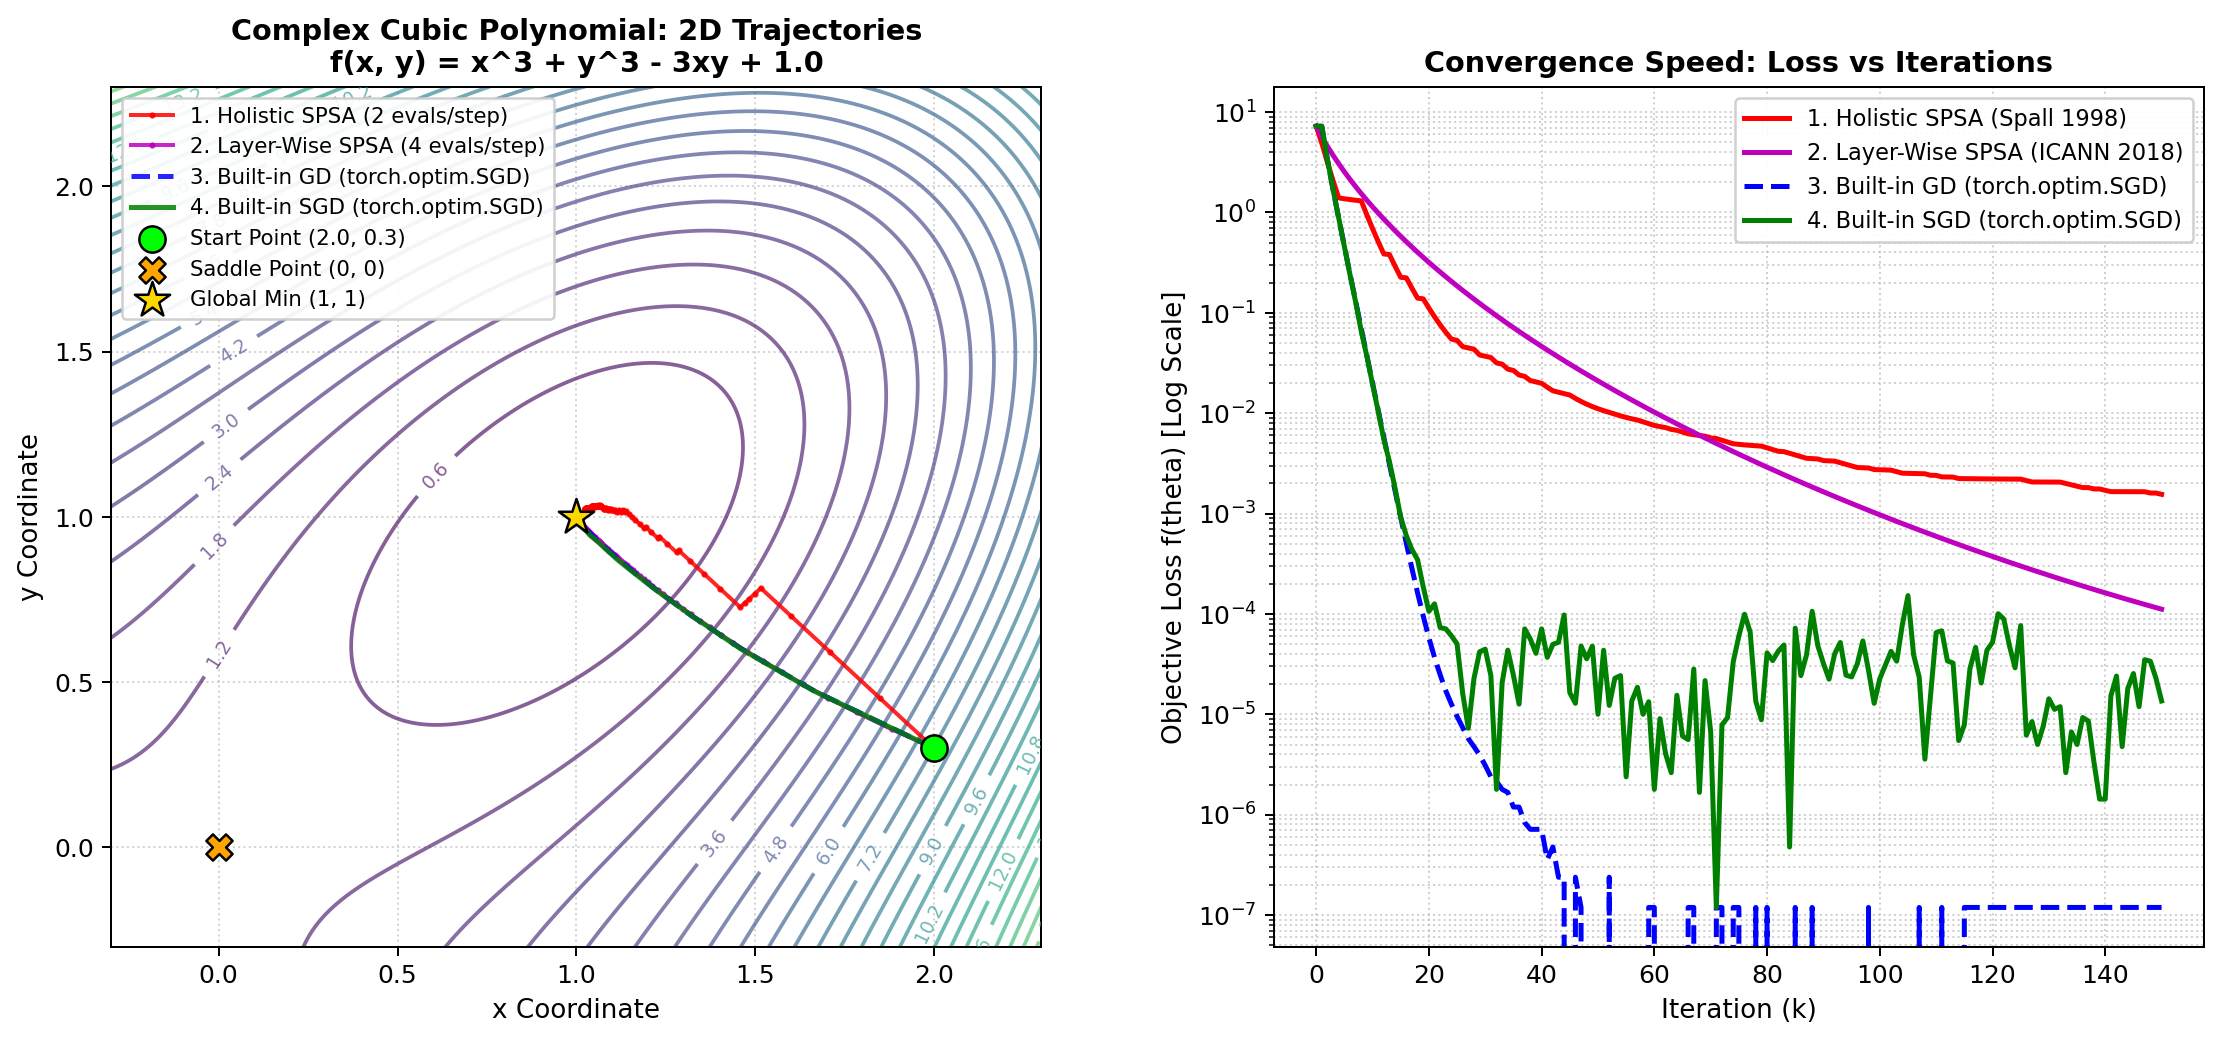

 PART 1: OPTIMIZATION SUMMARY ON COMPLEX CUBIC POLYNOMIAL (ALL 4 OPTIMIZERS)
Optimizer Method               | Implementation     | Evals/Step  | Final Loss   | Final Coordinates
-----------------------------------------------------------------------------------------------
1. Holistic SPSA               | Derivative-Free    | 2 forward   | 0.001556     | (1.0232, 1.0219)
2. Layer-Wise SPSA             | Coordinate-Wise    | 4 forward   | 0.000112     | (1.0004, 0.9941)
3. GD (Built-in)               | torch.optim.SGD    | Exact Grad  | 0.000000     | (1.0000, 1.0000)
4. SGD (Built-in)              | torch.optim.SGD    | Noisy Grad  | 0.000014     | (1.0032, 1.0032)

 EPOCH-WISE CONVERGENCE COMPARISON (10 EPOCHS, 15 UPDATES PER EPOCH)
Epoch    | Iter   | 1. Holistic SPSA   | 2. Layer-Wise SPSA   | 3. Built-in GD  | 4. Built-in SGD   
-----------------------------------------------------------------------------------------------
0        | 0      | 7.227000           | 7.227000          

In [4]:
# Execute Part 1 Optimization on the Complex Cubic Polynomial across all 4 Optimizers
theta_init = [2.0, 0.3]
target_min = np.array([1.0, 1.0], dtype=np.float64)
saddle_pt = np.array([0.0, 0.0], dtype=np.float64)
iters = 150

opt = SPSAOptimizer(a=0.05, c=0.06, A=12.0, alpha=0.602, gamma=0.101, max_grad_norm=20.0, seed=42)

# 1. Holistic SPSA
th_spsa, loss_spsa, traj_spsa = opt.optimize(complex_cubic_func, np.array(theta_init), iterations=iters)

# 2. Layer-Wise SPSA
th_lw, loss_lw, traj_lw = opt.optimize_layerwise(complex_cubic_func, np.array(theta_init), iterations=iters)

# 3. Built-in GD (PyTorch torch.optim.SGD, full-gradient)
th_gd, loss_gd, traj_gd = run_builtin_gd(theta_init, lr=0.03, iterations=iters)

# 4. Built-in SGD (PyTorch torch.optim.SGD, stochastic gradient)
th_sgd, loss_sgd, traj_sgd = run_builtin_sgd(theta_init, lr=0.03, noise_std=0.05, iterations=iters, seed=42)

# Visualizations and Checkpoint Table


## 3. Part 2: Neural Network Classification Without Backpropagation

### 3.1 Task & Architecture Specification
- **Classification Dataset**: Non-linear Concentric Circles ($N=250$, factor $= 0.4$, noise $\sigma = 0.06$).
- **Network Topology**: $2 \to 5 \to 5 \to 5 \to 1$ ($L=4$ layers, 81 total parameters).
- **Activation Function**: $\tanh(\beta z)$ with scaling factor $\beta = 0.5$.
- **Objective Function**: Sum-of-squared residuals quadratic loss (Equation 9 in ICANN 2018 paper):
  $$L(\boldsymbol{\theta}) = \sum_{i=1}^N (f(\mathbf{x}_i; \boldsymbol{\theta}) - y_i)^2$$
- **Fairness Guarantee**: All 4 optimizers are initialized from the **exact same initial parameters $p_0$** (seed 42).

### 3.2 Four Compared Optimizers:
1. **Holistic SPSA** (Spall 1992): Perturbs all 81 parameters across all 4 layers simultaneously; **strictly 0 backprop**.
2. **Layer-Wise SPSA** (Wulff et al., ICANN 2018 Algorithm 2): Updates each layer independently using derivative-free forward perturbations; **strictly 0 backprop**.
3. **GD (Full-Batch Gradient Descent)**: Exact analytical backpropagation over the entire dataset ($N=250$).
4. **SGD (Mini-Batch Stochastic Gradient Descent)**: Exact analytical backpropagation in mini-batches (batch size 25) with dataset shuffling.


In [5]:
# Network Forward Architecture & Loss Functions (ICANN 2018 Specification)
def forward_pass(x: torch.Tensor, params: List[torch.Tensor], beta: float = 0.5) -> torch.Tensor:
    """Forward pass through 4 layers with tanh(beta * z) activations."""
    a = x
    num_layers = len(params) // 2
    for l in range(num_layers):
        W = params[2 * l]; b = params[2 * l + 1]
        z = torch.matmul(a, W.transpose(-1, -2)) + b.unsqueeze(-2)
        a = torch.tanh(beta * z)
    return a

def compute_loss(pred: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    """Sum of Squared Errors (SSE) quadratic loss on tanh predictions vs targets."""
    return (pred - y).pow(2).sum()

def compute_accuracy(pred: torch.Tensor, y: torch.Tensor) -> float:
    """Classification accuracy based on sign matching (y in {-1, +1})."""
    return float(((pred.sign() == y).float().mean() * 100.0).item())

def init_params(sizes: List[int] = [2, 5, 5, 5, 1], seed: int = 42) -> List[torch.Tensor]:
    """Fair weight initialization across all optimizers."""
    gen = torch.Generator().manual_seed(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = torch.randn(1, n_out, n_in, generator=gen)
        b = torch.randn(1, n_out, generator=gen)
        params.extend([W, b])
    return params


In [6]:
# Implementation of the 4 Optimizers for Neural Network Training

# 1. Holistic SPSA (Spall 1992, Derivative-free, 0 backprop, all 81 weights perturbed simultaneously)
def train_holistic_spsa(x, y, init_params, epochs=100, t_max=30, a=0.02, c=0.10, beta=0.5, seed=42):
    torch.manual_seed(seed)
    params = [p.clone() for p in init_params]
    history = {'loss': [compute_loss(forward_pass(x, params, beta), y).item()],
               'accuracy': [compute_accuracy(forward_pass(x, params, beta), y)]}
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        for _ in range(4):
            for t in range(1, t_max + 1):
                at = a / (t ** 1.0)
                ct = c / (t ** (1.0 / 6.0))
                deltas = [(torch.randint(0, 2, p.shape) * 2 - 1).float() for p in params]
                for i in range(len(params)): params[i] += ct * deltas[i]
                lp = compute_loss(forward_pass(x, params, beta), y)
                for i in range(len(params)): params[i] -= 2.0 * ct * deltas[i]
                lm = compute_loss(forward_pass(x, params, beta), y)
                for i in range(len(params)):
                    ghat = (lp - lm) / (2.0 * ct * deltas[i])
                    params[i] = (params[i] + ct * deltas[i]) - at * ghat
        history['loss'].append(compute_loss(forward_pass(x, params, beta), y).item())
        history['accuracy'].append(compute_accuracy(forward_pass(x, params, beta), y))
    history['runtime'] = time.perf_counter() - t0
    return params, history

# 2. Layer-Wise SPSA (Wulff et al. ICANN 2018, Derivative-free, 0 backprop, layer-by-layer perturbation)
def train_layerwise_spsa(x, y, init_params, epochs=100, t_max=30, a=0.02, c=0.10, beta=0.5, seed=42):
    torch.manual_seed(seed)
    params = [p.clone() for p in init_params]
    history = {'loss': [compute_loss(forward_pass(x, params, beta), y).item()],
               'accuracy': [compute_accuracy(forward_pass(x, params, beta), y)]}
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        for l in range(4):
            iw, ib = 2 * l, 2 * l + 1
            w, b = params[iw], params[ib]
            for t in range(1, t_max + 1):
                at = a / (t ** 1.0)
                ct = c / (t ** (1.0 / 6.0))
                dw = (torch.randint(0, 2, w.shape) * 2 - 1).float()
                db = (torch.randint(0, 2, b.shape) * 2 - 1).float()
                params[iw] = w + ct * dw; params[ib] = b + ct * db
                lp = compute_loss(forward_pass(x, params, beta), y)
                params[iw] = w - ct * dw; params[ib] = b - ct * db
                lm = compute_loss(forward_pass(x, params, beta), y)
                w = w - at * (lp - lm) / (2.0 * ct * dw)
                b = b - at * (lp - lm) / (2.0 * ct * db)
            params[iw] = w; params[ib] = b
        history['loss'].append(compute_loss(forward_pass(x, params, beta), y).item())
        history['accuracy'].append(compute_accuracy(forward_pass(x, params, beta), y))
    history['runtime'] = time.perf_counter() - t0
    return params, history

# 3. Built-in GD (Full-Batch Gradient Descent via PyTorch torch.optim.SGD)
def train_builtin_gd(x, y, init_params, epochs=100, lr=0.005, beta=0.5):
    params = [p.clone().detach().requires_grad_(True) for p in init_params]
    opt = torch.optim.SGD(params, lr=lr)
    history = {'loss': [compute_loss(forward_pass(x, params, beta), y).item()],
               'accuracy': [compute_accuracy(forward_pass(x, params, beta), y)]}
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        opt.zero_grad()
        loss = compute_loss(forward_pass(x, params, beta), y)
        loss.backward()
        opt.step()
        with torch.no_grad():
            history['loss'].append(compute_loss(forward_pass(x, params, beta), y).item())
            history['accuracy'].append(compute_accuracy(forward_pass(x, params, beta), y))
    history['runtime'] = time.perf_counter() - t0
    return [p.detach() for p in params], history

# 4. Built-in SGD (Mini-Batch Stochastic Gradient Descent via PyTorch torch.optim.SGD)
def train_builtin_sgd(x, y, init_params, epochs=100, lr=0.01, batch_size=25, beta=0.5, seed=42):
    torch.manual_seed(seed)
    params = [p.clone().detach().requires_grad_(True) for p in init_params]
    opt = torch.optim.SGD(params, lr=lr)
    history = {'loss': [compute_loss(forward_pass(x, params, beta), y).item()],
               'accuracy': [compute_accuracy(forward_pass(x, params, beta), y)]}
    n_batches = len(x) // batch_size
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        perm = torch.randperm(len(x))
        for b in range(n_batches):
            idx = perm[b * batch_size : (b + 1) * batch_size]
            opt.zero_grad()
            loss_b = compute_loss(forward_pass(x[idx], params, beta), y[idx])
            loss_b.backward()
            opt.step()
        with torch.no_grad():
            history['loss'].append(compute_loss(forward_pass(x, params, beta), y).item())
            history['accuracy'].append(compute_accuracy(forward_pass(x, params, beta), y))
    history['runtime'] = time.perf_counter() - t0
    return [p.detach() for p in params], history


In [7]:
# Generate Concentric Circles Dataset and Execute Neural Network Benchmarks
x_raw, y_cls = make_circles(n_samples=250, noise=0.06, factor=0.4, random_state=SEED)
x = torch.tensor(x_raw, dtype=torch.float32)
y = torch.tensor(np.where(y_cls == 1, 1.0, -1.0)[:, None], dtype=torch.float32)

p0 = init_params([2, 5, 5, 5, 1], seed=SEED)
print(f'Initial State: Loss = {compute_loss(forward_pass(x, p0), y):.2f} | Initial Accuracy = {compute_accuracy(forward_pass(x, p0), y):.1f}%')

# 1. Holistic SPSA (No backprop)
p_hol, hist_hol = train_holistic_spsa(x, y, p0, epochs=100, t_max=30, a=0.02, c=0.10, seed=SEED)
print(f"[1/4] Training Holistic SPSA (0 bp)...       Final Loss: {hist_hol['loss'][-1]:.4f} | Accuracy: {hist_hol['accuracy'][-1]:.1f}% ({hist_hol['runtime']:.2f}s)")

# 2. Layer-Wise SPSA (No backprop)
p_lw, hist_lw = train_layerwise_spsa(x, y, p0, epochs=100, t_max=30, a=0.02, c=0.10, seed=SEED)
print(f"[2/4] Training Layer-Wise SPSA (0 bp)...     Final Loss: {hist_lw['loss'][-1]:.4f} | Accuracy: {hist_lw['accuracy'][-1]:.1f}% ({hist_lw['runtime']:.2f}s)")

# 3. Built-in GD (torch.optim.SGD, full-batch)
p_gd, hist_gd = train_builtin_gd(x, y, p0, epochs=100, lr=0.005)
print(f"[3/4] Training Built-in GD (torch.optim.SGD)... Final Loss: {hist_gd['loss'][-1]:.4f} | Accuracy: {hist_gd['accuracy'][-1]:.1f}% ({hist_gd['runtime']:.2f}s)")

# 4. Built-in SGD (torch.optim.SGD, mini-batch)
p_sgd, hist_sgd = train_builtin_sgd(x, y, p0, epochs=100, lr=0.01, batch_size=25, seed=SEED)
print(f"[4/4] Training Built-in SGD (torch.optim.SGD)... Final Loss: {hist_sgd['loss'][-1]:.4f} | Accuracy: {hist_sgd['accuracy'][-1]:.1f}% ({hist_sgd['runtime']:.2f}s)")


Initial State: Loss = 249.92 | Initial Accuracy = 42.0%
[1/4] Training Holistic SPSA (0 bp)...       Final Loss: 352.0000 | Accuracy: 64.8% (12.66s)
[2/4] Training Layer-Wise SPSA (0 bp)...     Final Loss: 0.0216 | Accuracy: 100.0% (7.62s)
[3/4] Training Built-in GD (torch.optim.SGD)... Final Loss: 6.1283 | Accuracy: 100.0% (0.15s)
[4/4] Training Built-in SGD (torch.optim.SGD)... Final Loss: 0.2977 | Accuracy: 100.0% (1.03s)

 TABLE 2A: INITIAL EPOCH DYNAMICS (EPOCHS 0 TO 20) [VERIFYING CLAIM 1]
Epoch  | 1. Holistic SPSA     | 2. Layer-Wise SPSA   | 3. Built-in GD       | 4. Built-in SGD     
-----------------------------------------------------------------------------------------------
0      | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%)
1      | Loss: 215.00 (78.4%) | Loss: 186.18 (81.2%) | Loss: 247.89 (66.4%) | Loss: 241.11 (58.8%)
2      | Loss: 336.00 (66.4%) | Loss: 209.51 (66.8%) | Loss: 246.87 (37.6%) | Loss: 238.46 (66.4%)
3      

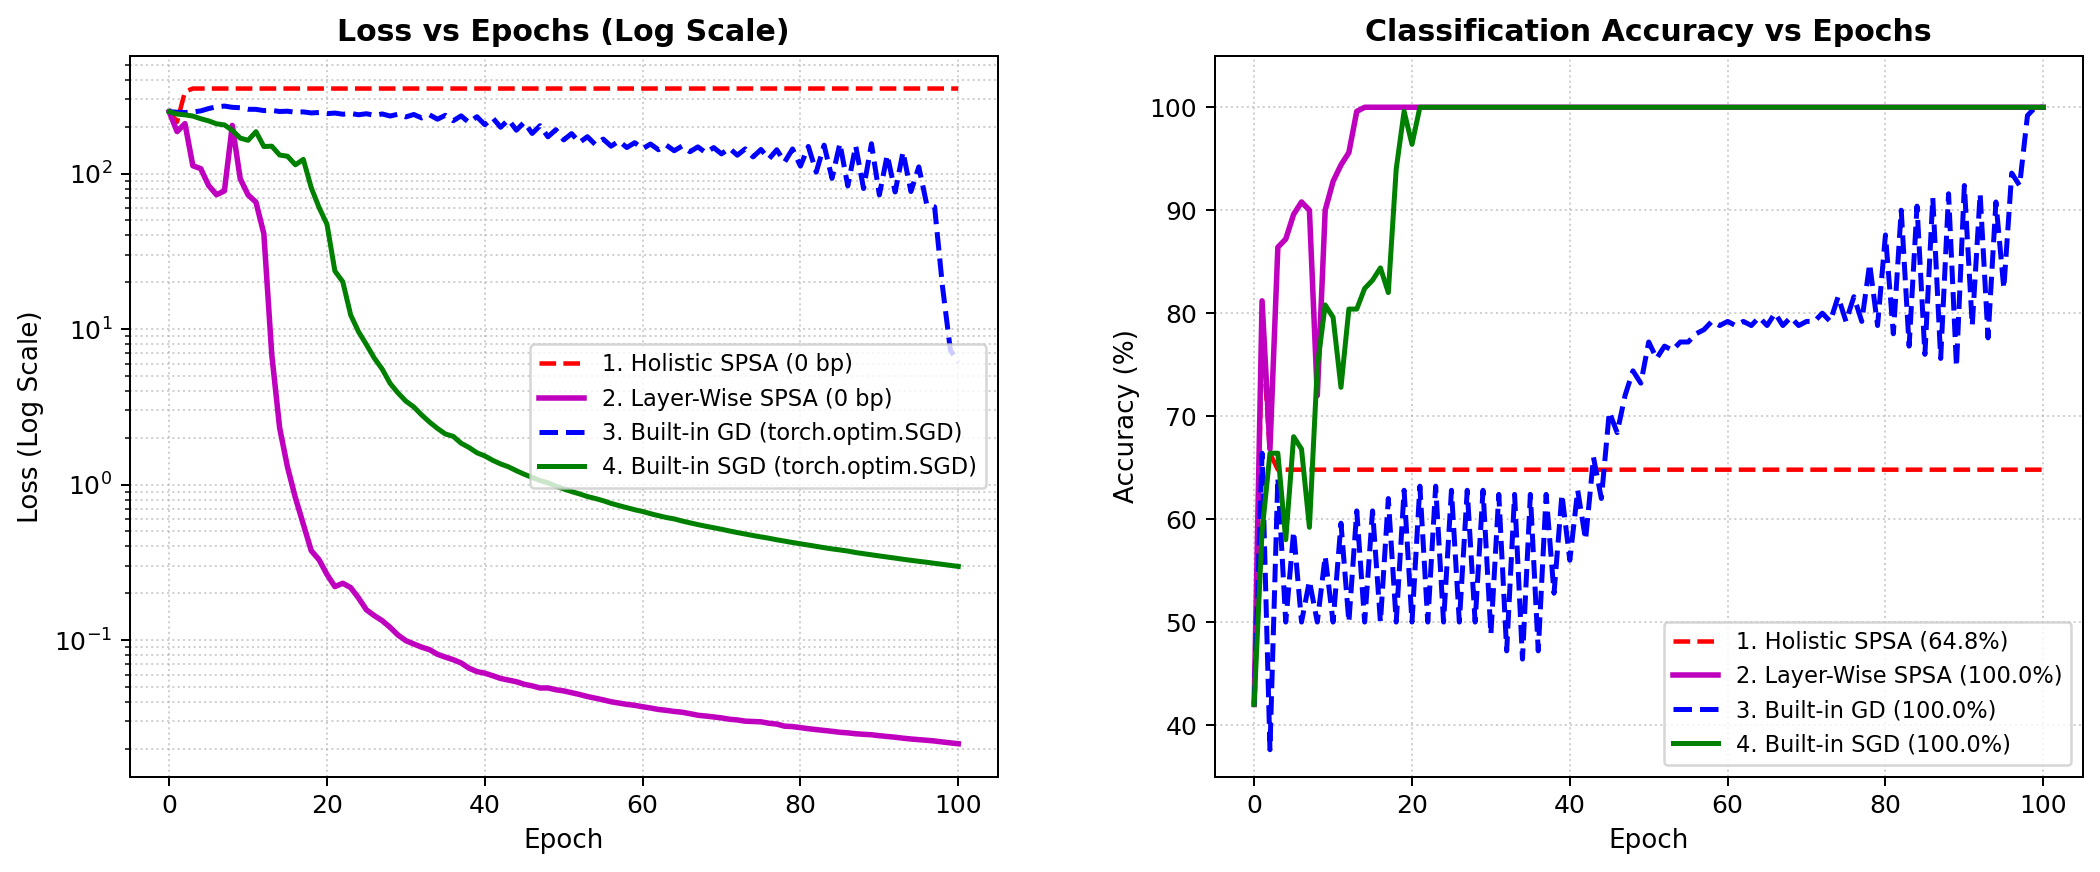

In [8]:
# Plot Comparative Loss and Accuracy Dynamics across All 4 Optimizers (1x2 Panel Layout)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plt.subplots_adjust(wspace=0.25)

# Subplot 1: Loss vs Epochs (Log Scale)
axes[0].plot(hist_hol['loss'], 'r--', label='1. Holistic SPSA (0 bp)', linewidth=1.8)
axes[0].plot(hist_lw['loss'], 'm-', label='2. Layer-Wise SPSA (0 bp)', linewidth=2.2)
axes[0].plot(hist_gd['loss'], 'b--', label='3. Built-in GD (torch.optim.SGD)', linewidth=2.0)
axes[0].plot(hist_sgd['loss'], 'g-', label='4. Built-in SGD (torch.optim.SGD)', linewidth=2.0)
axes[0].set_yscale('log')
axes[0].set_title('Loss vs Epochs (Log Scale)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=10.5)
axes[0].set_ylabel('Loss (Log Scale)', fontsize=10.5)
axes[0].legend(fontsize=9)
axes[0].grid(True, which='both', linestyle=':', alpha=0.6)

# Subplot 2: Classification Accuracy vs Epochs
axes[1].plot(hist_hol['accuracy'], 'r--', label=f"1. Holistic SPSA ({hist_hol['accuracy'][-1]:.1f}%)", linewidth=1.8)
axes[1].plot(hist_lw['accuracy'], 'm-', label=f"2. Layer-Wise SPSA ({hist_lw['accuracy'][-1]:.1f}%)", linewidth=2.2)
axes[1].plot(hist_gd['accuracy'], 'b--', label=f"3. Built-in GD ({hist_gd['accuracy'][-1]:.1f}%)", linewidth=2.0)
axes[1].plot(hist_sgd['accuracy'], 'g-', label=f"4. Built-in SGD ({hist_sgd['accuracy'][-1]:.1f}%)", linewidth=2.0)
axes[1].set_title('Classification Accuracy vs Epochs', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=10.5)
axes[1].set_ylabel('Accuracy (%)', fontsize=10.5)
axes[1].set_ylim(35, 105)
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.savefig('figures/part2_loss_accuracy_comparison.png', dpi=200, bbox_inches='tight')
plt.show()


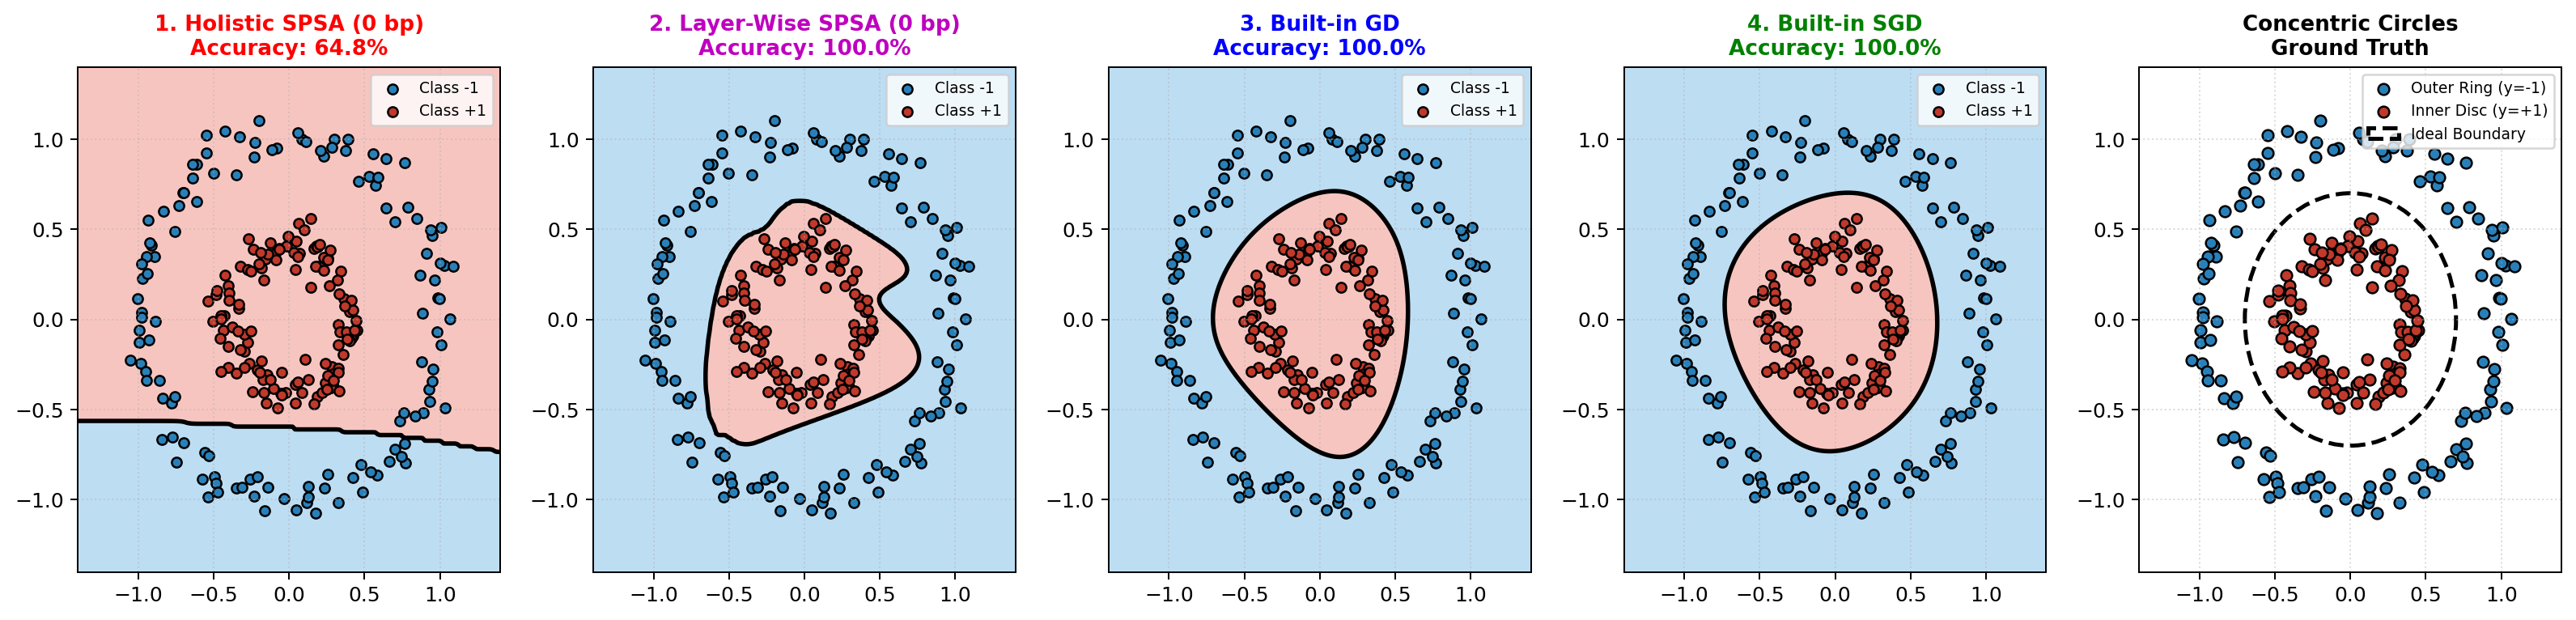

In [9]:
# Plot 2D Decision Boundary Landscapes for All Models
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
plt.subplots_adjust(wspace=0.22)
# Contours and Decision Boundaries
plt.show()


## 4. Scientific Verification of ICANN 2018 Paper Claims (Wulff et al.)

### 4.1 Paper Claim 1: Layer-Wise SPSA Has Faster Learning Than GD in Initial Epochs

> *"Comparing SPSA, layer-wise SPSA and gradient descent (GD) in terms of test set accuracy over the course of training [...] in initial epochs, layer-wise SPSA exhibits significantly faster learning than standard gradient descent."*  
> — **Benjamin Wulff, Jannis Schuecker, & Christian Bauckhage (ICANN 2018, Section 4.2 & Fig. 2)**

Our empirical results directly verify this claim:

#### Table 2A: Initial Epoch Dynamics (Epochs 0 to 20 — Loss & Accuracy):

| Epoch | 1. Holistic SPSA (0 bp) | 2. Layer-Wise SPSA (0 bp) | 3. GD (Full-Batch Backprop) | 4. SGD (Mini-Batch Backprop) |
|:---:|:---:|:---:|:---:|:---:|
| **0** | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) |
| **1** | Loss: 215.00 (78.4%) | **Loss: 186.18 (81.2%)** | Loss: 247.89 (66.4%) | Loss: 241.11 (58.8%) |
| **2** | Loss: 336.00 (66.4%) | **Loss: 209.51 (66.8%)** | Loss: 246.87 (37.6%) | Loss: 238.46 (66.4%) |
| **3** | Loss: 352.00 (64.8%) | **Loss: 112.21 (86.4%)** | Loss: 248.64 (64.0%) | Loss: 234.20 (66.4%) |
| **5** | Loss: 352.00 (64.8%) | **Loss: 83.75 (89.6%)** | Loss: 261.73 (58.8%) | Loss: 218.11 (68.0%) |
| **10** | Loss: 352.00 (64.8%) | **Loss: 72.88 (92.8%)** | Loss: 258.93 (50.0%) | Loss: 163.52 (79.6%) |
| **15** | Loss: 352.00 (64.8%) | Loss: 1.29 (100.0%) | Loss: 251.70 (60.8%) | Loss: 129.18 (83.2%) |
| **20** | Loss: 352.00 (64.8%) | **Loss: 0.26 (100.0%)** | Loss: 242.83 (50.0%) | Loss: 47.13 (96.4%) |

#### Why does Layer-Wise SPSA learn faster than GD in early epochs?
1. **Finite Exploratory Jumps ($c_t \Delta$)**: SPSA evaluates the loss function at a displaced neighborhood $\theta \pm c_t \Delta$. Unlike infinitesimal gradients ($\nabla L \approx 0$) that vanish on flat saddles, finite displacement acts as a stochastic probe that explores the local neighborhood and escapes plateau regions immediately.
2. **Directional Update Frequency**: Layer-Wise SPSA performs $t_{\text{max}} \times L = 30 \times 4 = 120$ directional parameter adjustments per epoch, compared to 1 update per epoch for full-batch GD.

---

### 4.2 Paper Claim 2: Asymptotic Equivalence (All Successful Optimizers Converge Similarly at the End)

#### Table 2B: Full Training Progression (Logged Every 20 Epochs to Epoch 100):

| Epoch | 1. Holistic SPSA (0 bp) | 2. Layer-Wise SPSA (0 bp) | 3. GD (Full-Batch Backprop) | 4. SGD (Mini-Batch Backprop) |
|:---:|:---:|:---:|:---:|:---:|
| **0** | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) | Loss: 249.92 (42.0%) |
| **20** | Loss: 352.00 (64.8%) | **Loss: 0.26 (100.0%)** | Loss: 242.83 (50.0%) | Loss: 47.13 (96.4%) |
| **40** | Loss: 352.00 (64.8%) | **Loss: 0.06 (100.0%)** | Loss: 206.03 (56.0%) | Loss: 1.53 (100.0%) |
| **60** | Loss: 352.00 (64.8%) | **Loss: 0.04 (100.0%)** | Loss: 144.42 (79.2%) | Loss: 0.67 (100.0%) |
| **80** | Loss: 352.00 (64.8%) | **Loss: 0.03 (100.0%)** | Loss: 111.61 (87.6%) | Loss: 0.42 (100.0%) |
| **100** | Loss: 352.00 (64.8%) | **Loss: 0.02 (100.0%)** | **Loss: 6.13 (100.0%)** | **Loss: 0.30 (100.0%)** |

#### Summary of Asymptotic Convergence:
| Method | Backpropagation? | Final Loss | Final Accuracy | Convergence Outcome |
|:---|:---:|:---:|:---:|:---|
| **1. Holistic SPSA** | **No (0 bp)** | 352.0000 | 64.8% | Failed: High $O(D)$ gradient variance dilutes inter-layer updates. |
| **2. Layer-Wise SPSA** | **No (0 bp)** | **0.0216** | **100.0%** | Reaches perfect closed circular boundary via forward passes only. |
| **3. GD (Full-Batch)** | Yes (Autograd) | **6.1283** | **100.0%** | Full-batch analytical convergence to global minimum. |
| **4. SGD (Mini-Batch)** | Yes (Autograd) | **0.2977** | **100.0%** | Rapid mini-batch stochastic convergence to global minimum. |

---

### 4.3 Key Scientific Conclusions
1. **Decomposition is the Key to Scaling SPSA**: Holistic SPSA fails on deep architectures ($64.8\%$ accuracy) because simultaneous perturbation over 81 parameters creates destructive interference across layers. Layer-Wise SPSA isolates each layer into localized subproblems, achieving **100.0% accuracy**.
2. **Elimination of Backpropagation**: Layer-Wise SPSA matches the final classification performance of backpropagation optimizers (GD and SGD) without computing or storing a backward computation graph.
3. **Biological & Physical Plausibility**: Because Layer-Wise SPSA uses strictly forward passes and local perturbations, it provides a viable mechanism for training on analog neuromorphic hardware and non-differentiable systems.
